In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("Libraries imported successfully!")


TensorFlow Version: 2.21.0
NumPy Version: 2.4.6
Libraries imported successfully!


In [ ]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training Images: (60000, 28, 28)
Training Labels: (60000,)
Testing Images: (10000, 28, 28)
Testing Labels: (10000,)


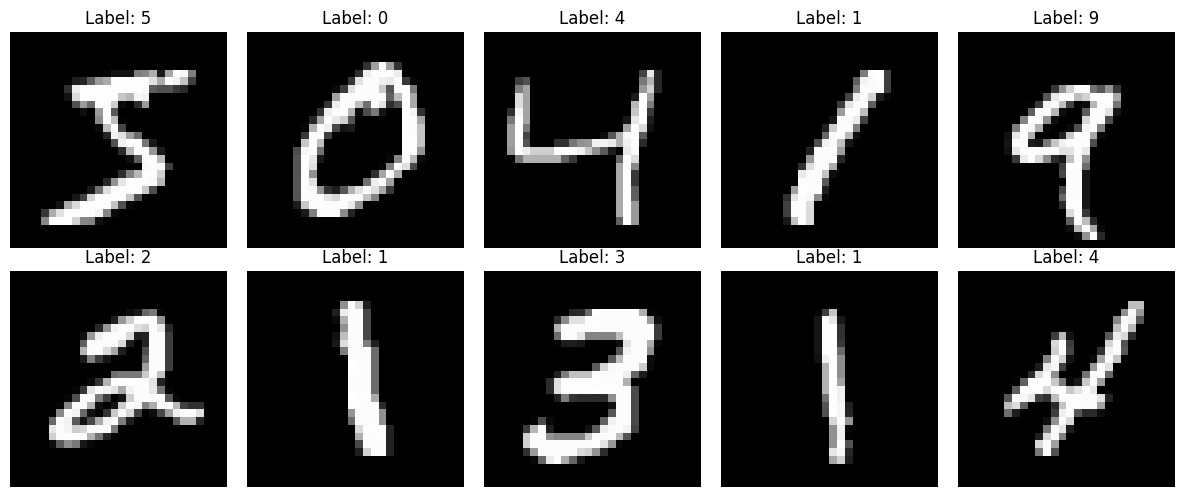

In [ ]:

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()


0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64


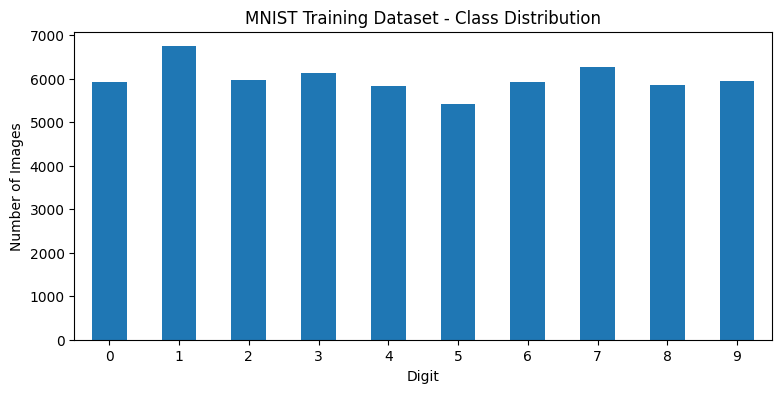

In [ ]:

class_counts = pd.Series(y_train).value_counts().sort_index()

print(class_counts)

class_counts.plot(kind='bar', figsize=(9, 4))
plt.title("MNIST Training Dataset - Class Distribution")
plt.xlabel("Digit")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.show()


In [ ]:

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Training data range:", X_train.min(), "to", X_train.max())
print("Testing data range:", X_test.min(), "to", X_test.max())


Training data range: 0.0 to 1.0
Testing data range: 0.0 to 1.0


In [ ]:

X_train_flat = X_train.reshape(X_train.shape[0], 784)
X_test_flat = X_test.reshape(X_test.shape[0], 784)

print("Original image shape:", X_train.shape)
print("Flattened training shape:", X_train_flat.shape)
print("Flattened testing shape:", X_test_flat.shape)


Original image shape: (60000, 28, 28)
Flattened training shape: (60000, 784)
Flattened testing shape: (10000, 784)


In [ ]:
print("Unique labels:", np.unique(y_train))
print("Number of classes:", len(np.unique(y_train)))

print("First 10 labels:", y_train[:10])

Unique labels: [0 1 2 3 4 5 6 7 8 9]
Number of classes: 10
First 10 labels: [5 0 4 1 9 2 1 3 1 4]


In [ ]:

from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

print("Training samples:", X_train_final.shape[0])
print("Validation samples:", X_val.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 54000
Validation samples: 6000
Testing samples: 10000


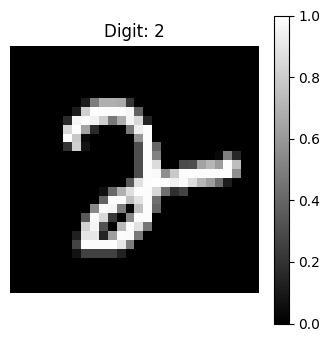

Pixel minimum: 0.0
Pixel maximum: 1.0


In [ ]:

plt.figure(figsize=(4, 4))
plt.imshow(X_train_final[0], cmap='gray')
plt.title(f"Digit: {y_train_final[0]}")
plt.colorbar()
plt.axis('off')
plt.show()

print("Pixel minimum:", X_train_final[0].min())
print("Pixel maximum:", X_train_final[0].max())


In [ ]:

model = keras.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
keras.layers.Input(shape=(28, 28))

<KerasTensor shape=(None, 28, 28), dtype=float32, sparse=False, ragged=False, name=keras_tensor_5>

In [ ]:
keras.layers.Flatten()

<Flatten name=flatten_1, built=False>

In [ ]:
keras.layers.Dense(128, activation='relu')

<Dense name=dense_3, built=False>

In [ ]:
keras.layers.Dense(10, activation='softmax')

<Dense name=dense_4, built=False>

In [ ]:

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("ANN Model compiled successfully!")


ANN Model compiled successfully!


In [ ]:

print("Model Architecture:")
model.summary()

print("\nInput Shape:", model.input_shape)
print("Output Shape:", model.output_shape)
print("Total Parameters:", model.count_params())


Model Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)


Input Shape: (None, 28, 28)
Output Shape: (None, 10)
Total Parameters: 109386


In [ ]:

history = model.fit(
    X_train_final,
    y_train_final,
    epochs=10,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

print("Model training completed!")


Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9255 - loss: 0.2498 - val_accuracy: 0.9573 - val_loss: 0.1392
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9673 - loss: 0.1057 - val_accuracy: 0.9650 - val_loss: 0.1183
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9773 - loss: 0.0726 - val_accuracy: 0.9690 - val_loss: 0.1036
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9829 - loss: 0.0545 - val_accuracy: 0.9725 - val_loss: 0.0948
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9862 - loss: 0.0437 - val_accuracy: 0.9710 - val_loss: 0.1099
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9896 - loss: 0.0323 - val_accuracy: 0.9678 - val_loss: 0.1105
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9898 - loss: 0.0295 - val_accuracy: 0.9717 - val_loss: 0.1246
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9914 - loss: 0.0243 -

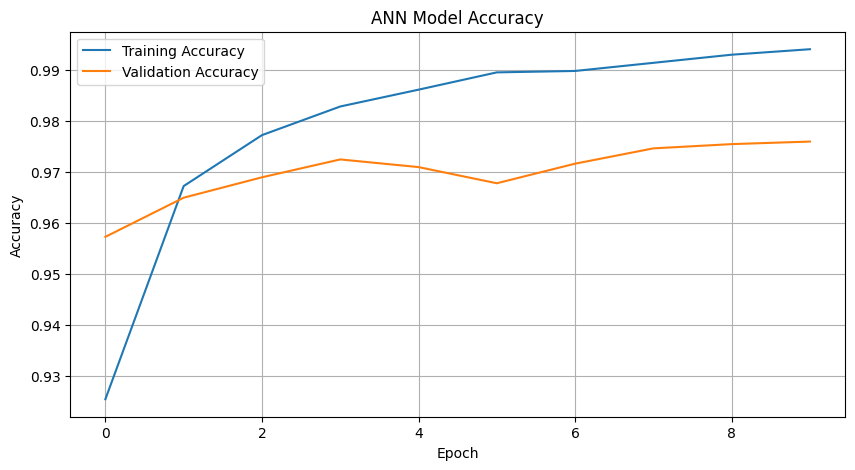

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('ANN Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()


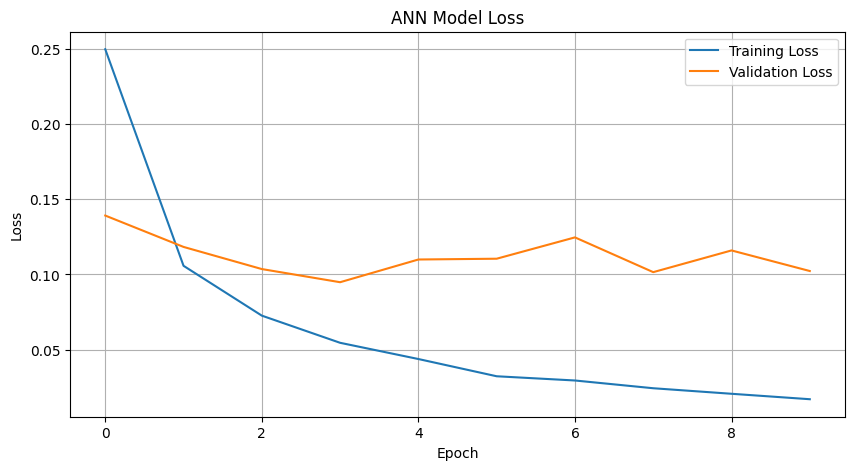

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('ANN Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

final_results = pd.DataFrame({
    'Epoch': range(1, 11),
    'Training Accuracy': history.history['accuracy'],
    'Validation Accuracy': history.history['val_accuracy'],
    'Training Loss': history.history['loss'],
    'Validation Loss': history.history['val_loss']
})

print(final_results.to_string(index=False))

print("\nFinal Training Accuracy:",
      round(history.history['accuracy'][-1] * 100, 2), "%")

print("Final Validation Accuracy:",
      round(history.history['val_accuracy'][-1] * 100, 2), "%")


 Epoch  Training Accuracy  Validation Accuracy  Training Loss  Validation Loss
     1           0.925519             0.957333       0.249783         0.139164
     2           0.967278             0.965000       0.105747         0.118303
     3           0.977259             0.969000       0.072604         0.103581
     4           0.982870             0.972500       0.054540         0.094831
     5           0.986167             0.971000       0.043748         0.109935
     6           0.989556             0.967833       0.032283         0.110458
     7           0.989833             0.971667       0.029472         0.124643
     8           0.991426             0.974667       0.024319         0.101528
     9           0.993019             0.975500       0.020636         0.115965
    10           0.994093             0.976000       0.017016         0.102271

Final Training Accuracy: 99.41 %
Final Validation Accuracy: 97.6 %


In [ ]:

model.save("handwritten_digit_ann.keras")

print("Trained ANN model saved successfully!")


Trained ANN model saved successfully!


In [ ]:

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9803 - loss: 0.0813
Test Loss: 0.0813
Test Accuracy: 98.03 %


In [ ]:

model.save("handwritten_digit_ann.keras")

from google.colab import files

files.download("handwritten_digit_ann.keras")


In [ ]:

y_pred_prob = model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Actual Labels:   ", y_test[:15])
print("Predicted Labels:", y_pred[:15])


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Actual Labels:    [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1]
Predicted Labels: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1]


In [ ]:

print(classification_report(
    y_test,
    y_pred,
    digits=4
))


              precision    recall  f1-score   support

           0     0.9868    0.9939    0.9903       980
           1     0.9956    0.9877    0.9916      1135
           2     0.9668    0.9864    0.9765      1032
           3     0.9842    0.9861    0.9852      1010
           4     0.9853    0.9542    0.9695       982
           5     0.9876    0.9798    0.9837       892
           6     0.9895    0.9802    0.9848       958
           7     0.9795    0.9737    0.9766      1028
           8     0.9764    0.9754    0.9759       974
           9     0.9530    0.9841    0.9683      1009

    accuracy                         0.9803     10000
   macro avg     0.9804    0.9802    0.9802     10000
weighted avg     0.9805    0.9803    0.9803     10000



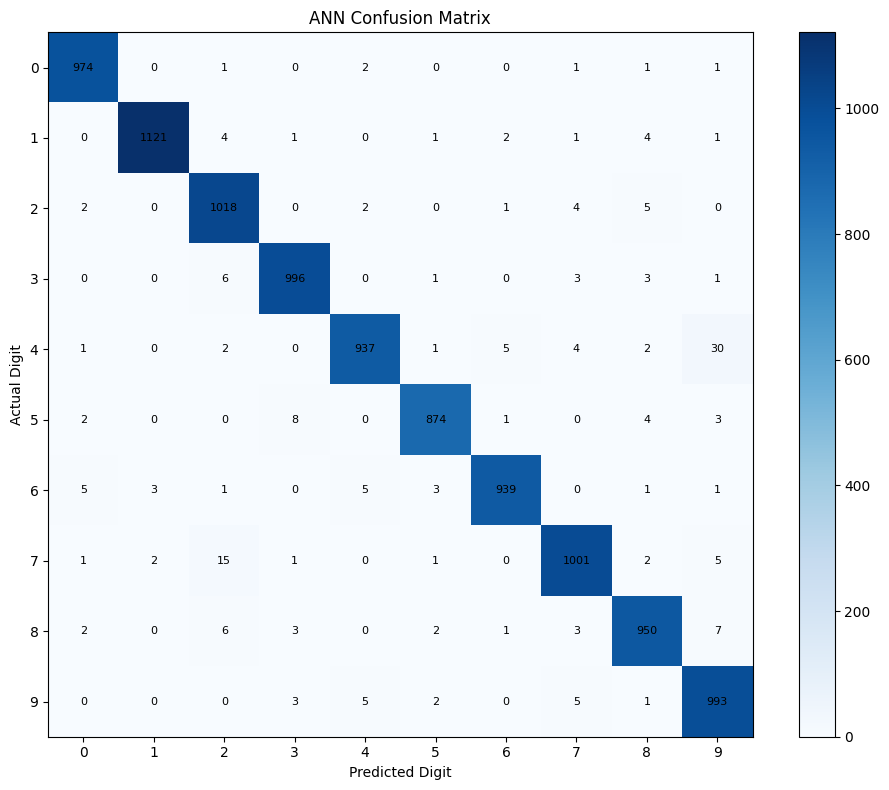

In [ ]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap='Blues')

plt.title("ANN Confusion Matrix")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")

plt.xticks(range(10))
plt.yticks(range(10))
plt.colorbar()

for i in range(10):
    for j in range(10):
        plt.text(
            j, i, cm[i, j],
            ha='center',
            va='center',
            fontsize=8
        )

plt.tight_layout()
plt.savefig("ANN_Confusion_Matrix.png", dpi=300)
plt.show()


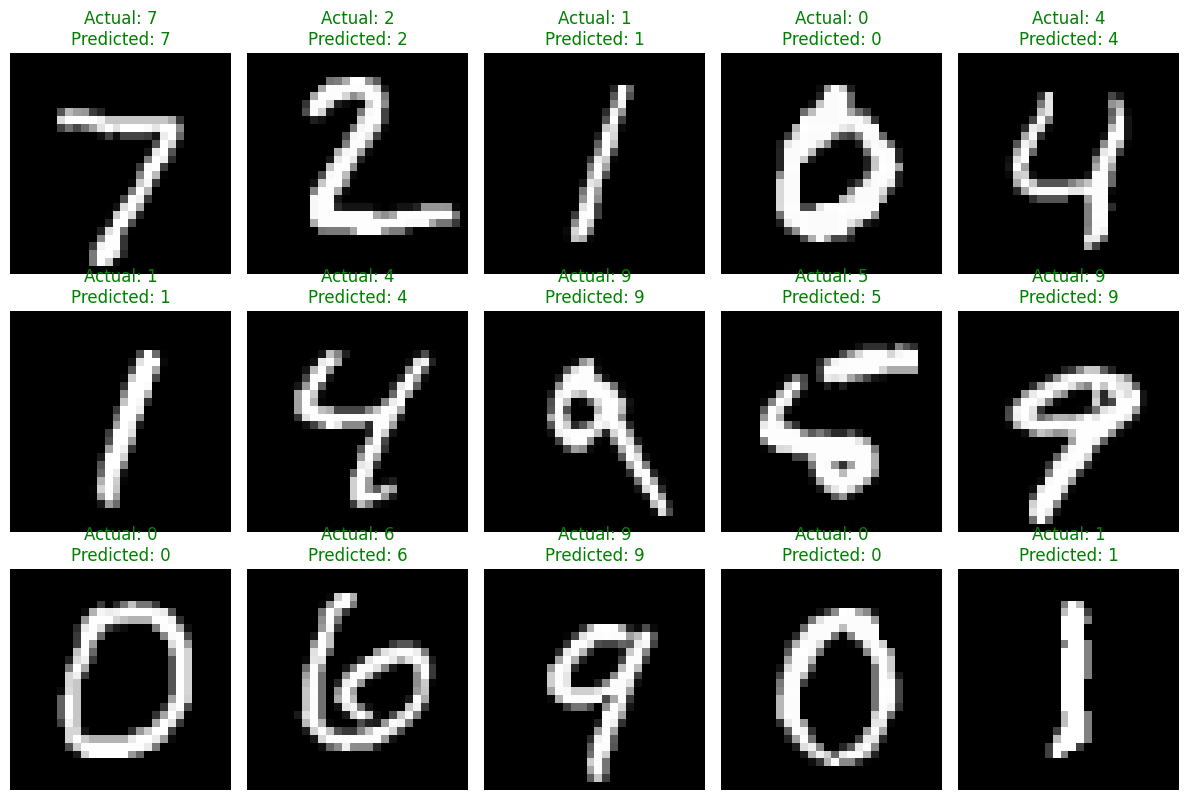

In [ ]:

plt.figure(figsize=(12, 8))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_test[i], cmap='gray')

    color = 'green' if y_test[i] == y_pred[i] else 'red'

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}",
        color=color
    )

    plt.axis('off')

plt.tight_layout()
plt.savefig("ANN_Sample_Predictions.png", dpi=300)
plt.show()


Total Test Images: 10000
Correct Predictions: 9803
Incorrect Predictions: 197


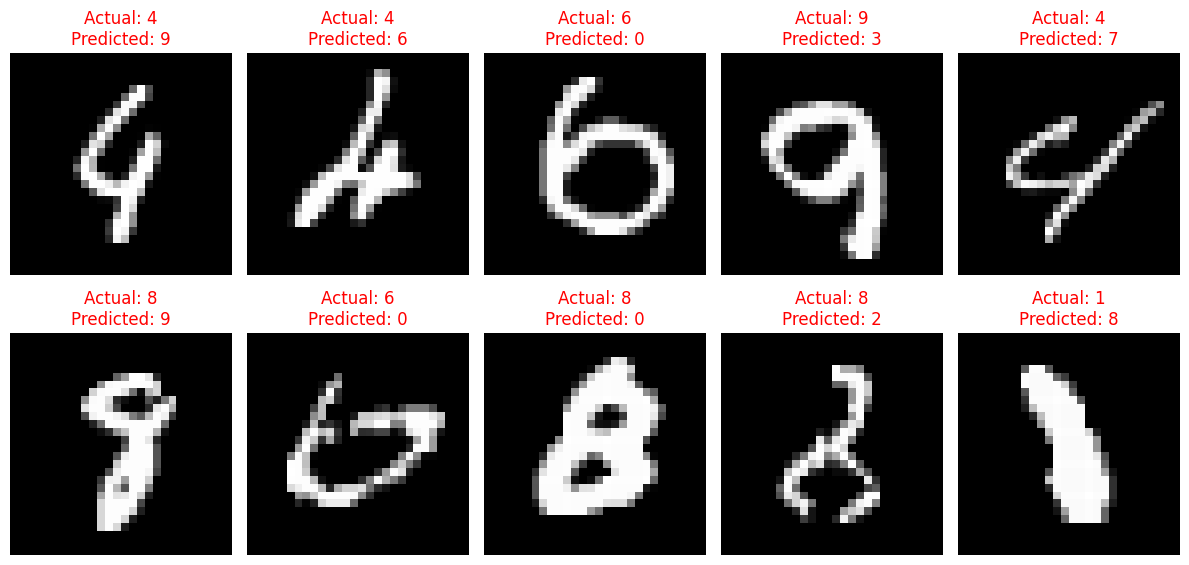

In [ ]:

wrong_indices = np.where(y_test != y_pred)[0]

correct_count = len(y_test) - len(wrong_indices)

print("Total Test Images:", len(y_test))
print("Correct Predictions:", correct_count)
print("Incorrect Predictions:", len(wrong_indices))

plt.figure(figsize=(12, 6))

for i in range(min(10, len(wrong_indices))):
    idx = wrong_indices[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[idx], cmap='gray')

    plt.title(
        f"Actual: {y_test[idx]}\nPredicted: {y_pred[idx]}",
        color='red'
    )

    plt.axis('off')

plt.tight_layout()
plt.savefig("ANN_Incorrect_Predictions.png", dpi=300)
plt.show()


In [ ]:

report = classification_report(
    y_test,
    y_pred,
    output_dict=True
)

pd.DataFrame(report).transpose().to_csv(
    "ANN_Classification_Report.csv"
)

pd.DataFrame(cm).to_csv(
    "ANN_Confusion_Matrix.csv",
    index=False
)

print("Evaluation results saved successfully!")


Evaluation results saved successfully!


In [ ]:

model.save("handwritten_digit_ann.keras")

from google.colab import files

files.download("handwritten_digit_ann.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>